In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
list_int64 = list(df.dtypes[df.dtypes == 'int64'].index)
for col in list_int64:
    df[col] = pd.to_numeric(df[col], errors = 'coerce')
    df[col] = df[col].fillna(0.0)
list_float64 = list(df.dtypes[df.dtypes == 'float64'].index)
for col in list_float64:
    df[col] = pd.to_numeric(df[col], errors = 'coerce')
    df[col] = df[col].fillna(0.0)
list_str = list(df.dtypes[df.dtypes == 'str'].index)
for col in list_str:
    df[col] = df[col].fillna('NA')

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
y_train = df_train.converted.values
y_val = df_val.converted.values

del df_train['converted']
del df_val['converted']

for col in list_int64[:-1] + list_float64:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f'{col}: {auc:.3f}')
dv = DictVectorizer(sparse=False)

train_dict = df_train[list_str + list_int64[:-1] + list_float64].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)
val_dict = df_val[list_str + list_int64[:-1] + list_float64].to_dict(orient='records')
X_val = dv.transform(val_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]


number_of_courses_viewed: 0.723
interaction_count: 0.765
annual_income: 0.608
lead_score: 0.788


In [6]:
auc = roc_auc_score(y_val, y_pred)
print(f'{auc:.3f}')

0.732


0.00: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.01: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.02: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.03: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.04: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.05: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.06: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.07: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.08: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.09: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.10: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.11: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.12: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.13: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.14: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.15: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.16: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.17: Precision = 0.586   Recall = 1.000   F1 = 0.739
0.18: Precision = 0.586   Re

(0.0, 1.05)

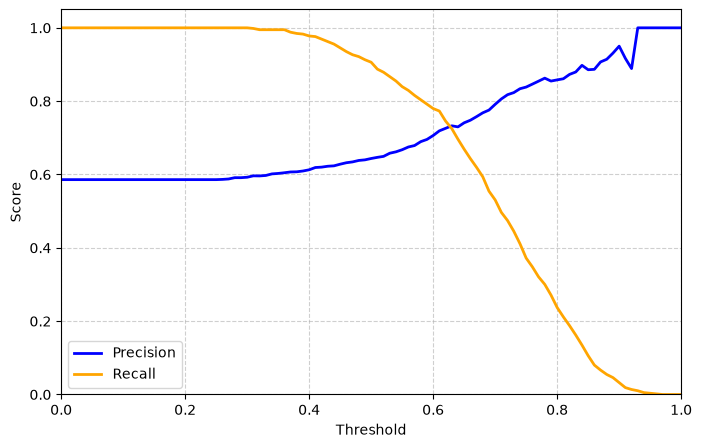

In [7]:
from sklearn.metrics import roc_curve
from sklearn.metrics import confusion_matrix

precision = []
recall = []
F1 = []
for thresh in np.linspace(0.0, 1.0, 101):
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred >= thresh).ravel()
    p = tp/(tp + fp) if (tp + fp) > 0 else 1.0
    r = tp/(tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2*(p*r)/(p+r)
    print(f'{thresh:.2f}: Precision = {p:.3f}   Recall = {r:.3f}   F1 = {f1:.3f}')
    precision.append(p)
    recall.append(r)
    F1.append(f1)

print(f'Maximum F1 = {np.linspace(0.0, 1.0, 101)[F1.index(max(F1))]:.2f}')
plt.figure(figsize=(8, 5))
plt.plot(np.linspace(0.0, 1.0, 101), precision, label='Precision', color='blue', linewidth=2)
plt.plot(np.linspace(0.0, 1.0, 101), recall, label='Recall', color='orange', linewidth=2)
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='best')
plt.xlim(0, 1)
plt.ylim(0, 1.05)

In [8]:
from sklearn.model_selection import KFold

In [16]:
def train(df, y):
    cat = df[list_str + list_int64[:-1] + list_float64].to_dict(orient='records')
    
    dv = DictVectorizer(sparse=False)
    dv.fit(cat)

    X = dv.transform(cat)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X, y)

    return dv, model


def predict(df, dv, model):
    cat = df[list_str + list_int64[:-1] + list_float64].to_dict(orient='records')
    
    X = dv.transform(cat)

    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [25]:
df_full_train = df_full_train.reset_index(drop=True)
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [26]:
aucs = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    y_train = df_train.converted.values

    df_val = df_full_train.iloc[val_idx]
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    rocauc = roc_auc_score(y_val, y_pred)
    aucs.append(rocauc)
print(f'{np.std(aucs):.4f}')

0.0069


In [31]:
def train(df, y, C=1.0):
    cat = df[list_str + list_int64[:-1] + list_float64].to_dict(orient='records')
    
    dv = DictVectorizer(sparse=False)
    dv.fit(cat)

    X = dv.transform(cat)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)

    return dv, model

In [32]:
nfolds = 5
kfold = KFold(n_splits=nfolds, shuffle=True, random_state=1)

for C in [0.000001, 0.001, 1]:
    aucs = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)
        
        auc = roc_auc_score(y_val, y_pred)
        aucs.append(auc)

    print('C=%s, auc = %0.3f ± %0.3f' % (C, np.mean(aucs), np.std(aucs)))

C=1e-06, auc = 0.617 ± 0.019
C=0.001, auc = 0.749 ± 0.010
C=1, auc = 0.732 ± 0.007
